# FoodLens Phase 4: Data Analysis and Insights

This notebook answers five questions using the five preserved Phase 3 cleaned
CSV files. It performs descriptive analysis of this sample, not population
inference, nutritional advice or further cleaning.

1. Which category has the highest median sugar content?
2. Which category has the highest median protein content?
3. Which products have the highest valid protein-per-100-kcal ratio?
4. Which categories have the highest nutritional data completeness?
5. How are Nutri-Score grades distributed across the four categories?

The Phase 2 notebook, Phase 3 transformation code and validation reports define
the source history and cleaning decisions. Phase 4 uses the explicit measurement
basis recovered in Phase 3, rather than assuming historical `_100g` suffixes prove
a mass basis. No dataset or prior notebook is written by this analysis.

## 1. Setup and read-only input checks

Run from the repository root or `notebooks/` using the project virtual environment.
Only five PNG charts are exported to `reports/figures/`. No API access is needed.
All data files and the previous notebook are checked for changes at the end.

In [1]:
from pathlib import Path
import hashlib
import platform
import textwrap

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / "data/cleaned/nutrition.csv").is_file()
             and (p / "src/clean_transform.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Run from the repository root or notebooks directory with the saved data available.")

def protected_snapshot():
    paths = [p for p in (ROOT / "data").rglob("*") if p.is_file()]
    paths.append(ROOT / "notebooks/01_eda.ipynb")
    return {p.relative_to(ROOT).as_posix():
            (hashlib.sha256(p.read_bytes()).hexdigest(), p.stat().st_size, p.stat().st_mtime_ns)
            for p in paths}

before = protected_snapshot()
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
chart_files = []
insights = {}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 85)
print(f"Python {platform.python_version()}, Pandas {pd.__version__}, NumPy {np.__version__}, Matplotlib {matplotlib.__version__}")

def save_chart(fig, filename):
    fig.savefig(FIGURES / filename, dpi=160, bbox_inches="tight", facecolor="white")
    chart_files.append(filename)
    plt.show()
    plt.close(fig)

Python 3.12.4, Pandas 3.0.6, NumPy 2.5.3, Matplotlib 3.11.2


In [2]:
expected_counts = {"products": 1987, "brands": 525, "categories": 4,
                   "product_categories": 2000, "nutrition": 1987}
tables = {name: pd.read_csv(ROOT / "data/cleaned" / f"{name}.csv",
                           dtype="string", keep_default_na=False, na_values=[""])
          for name in expected_counts}
products, brands, categories, links, nutrition = [tables[name] for name in expected_counts]
# CSV has no type metadata. Explicit string import preserves identifiers and literal NA labels.
nutrients = ["energy_kcal", "energy_kj", "protein_g", "carbohydrates_g", "sugars_g",
             "fat_g", "saturated_fat_g", "fiber_g", "salt_g"]
core = [name for name in nutrients if name != "energy_kj"]
for column in nutrition.columns:
    if column.endswith("_eligible") or column == "has_numeric_flags":
        assert nutrition[column].isin(["True", "False"]).all(), column
        nutrition[column] = nutrition[column].map({"True": True, "False": False}).astype("boolean")
    elif (column.endswith("_per_100") and not column.startswith("reported_")) or column in (
        "protein_g_per_100kcal", "sugar_to_carbohydrate_ratio", "nutrition_completeness_pct"
    ):
        nutrition[column] = pd.to_numeric(nutrition[column], errors="raise").astype("Float64")

for name, count in expected_counts.items():
    assert len(tables[name]) == count, f"Unexpected baseline in {name}; investigate before interpretation"
for table, key in [(products, "barcode"), (brands, "brand_id"), (categories, "category_id"), (nutrition, "barcode")]:
    assert table[key].notna().all() and table[key].is_unique
assert links.notna().all().all() and not links.duplicated(["barcode", "category_id"]).any()
assert set(nutrition.barcode) == set(products.barcode) == set(links.barcode)
assert set(products.brand_id.dropna()).issubset(set(brands.brand_id))
assert set(links.category_id) == set(categories.category_id)
assert products.barcode.str.fullmatch(r"[0-9]{8,14}").all()
assert int(products.barcode.str.startswith("0").sum()) == 83

eligibility_checks = []
for nutrient in nutrients:
    values = nutrition[f"{nutrient}_per_100"]
    eligible = nutrition[f"{nutrient}_eligible"]
    assert eligible.eq(values.notna() & nutrition[f"{nutrient}_flags"].isna()).all()
    assert np.isfinite(values[eligible]).all() and values[eligible].ge(0).all()
    eligibility_checks.append({"nutrient": nutrient,
        "reported_missing": int(nutrition[f"reported_{nutrient}_per_100"].isna().sum()),
        "numeric_null": int(values.isna().sum()), "numeric_eligible": int(eligible.sum()),
        "strict_100g_eligible": int((eligible & nutrition.measurement_basis.eq("100g")).sum())})
assert nutrition.measurement_basis.value_counts().to_dict() == {"100g": 1254, "unknown": 728, "100ml": 5}
input_copies = {name: table.copy(deep=True) for name, table in tables.items()}
display(pd.DataFrame({"rows": {name: len(t) for name, t in tables.items()},
                      "columns": {name: len(t.columns) for name, t in tables.items()}}))
display(pd.DataFrame([{"table": name, "column": col, "dtype": str(t[col].dtype)}
                      for name, t in tables.items() for col in t.columns]))
display(pd.DataFrame(eligibility_checks).set_index("nutrient"))
display(pd.Series({name: before[f"data/cleaned/{name}.csv"][0] for name in tables}, name="input_sha256").to_frame())

,rows,columns
products,1987,16
brands,525,2
categories,4,2
product_categories,2000,2
nutrition,1987,43


,table,column,dtype
0,products,barcode,string
1,products,product_name,string
2,products,original_product_name,string
3,products,brand_id,string
4,products,original_brands,string
...,...,...,...
60,nutrition,salt_g_eligible,boolean
61,nutrition,protein_g_per_100kcal,Float64
62,nutrition,sugar_to_carbohydrate_ratio,Float64
63,nutrition,nutrition_completeness_pct,Float64


,reported_missing,numeric_null,numeric_eligible,strict_100g_eligible
nutrient,,,,
energy_kcal,39,42,1865,1201
energy_kj,55,55,1849,1189
protein_g,43,43,1940,1231
carbohydrates_g,44,45,1934,1229
sugars_g,50,50,1932,1224
fat_g,41,41,1940,1231
saturated_fat_g,54,54,1931,1222
fiber_g,351,351,1636,1009
salt_g,66,67,1920,1219


,input_sha256
products,9bf2bb50247d0c376efea908a3ab5cc35a5a47dd9179e9bc092d3e943127c540
brands,fdc10c0761c5ad7563784cb6fa6ce290c17c510f1da74adff88c23c9f0e5cbde
categories,e411db0b835028ad5a46b3e96f703239eee48a625b3937c5269402323eac7d04
product_categories,d10e12fb8dc6c9be4f10cc367623f14e7766cbcfdded3a2282da47e0a75e4dea
nutrition,2ce5887ab59f9f6a69a6310366092b8fd51c0a9fad68a1fd525471ca81f35ff3


## 2. Join policy and analysis denominators

Overall statistics and product rankings use **one row per barcode**. Category
comparisons use every product-category membership, so the 13 overlapping products
contribute to both of their groups. Category totals must not be added as unique
product totals, and the groups are not independent samples.

Sugar/protein medians require the relevant eligible flag, a nonmissing value and
confirmed `100g` basis. We do not exclude an entire product because another field
is unavailable. Flags reflect the Phase 3 rules, not independently verified labels.
Ratios require eligible protein and kcal, positive kcal, and an explicit common
basis (`100g` or `100ml`); the denominator basis cancels. Unknown basis is excluded.

Completeness counts **reported coverage**, including values that later failed
quality screening. Nutri-Score uses all memberships, including unknown and not
applicable states. These two questions need no mass-basis filter.

In [3]:
order = ["breakfast-cereals", "yogurts", "biscuits", "cereal-bars"]
labels = categories.set_index("category_id").category_name.to_dict()
assert labels == {"breakfast-cereals": "Breakfast cereals", "yogurts": "Yogurts",
                  "biscuits": "Biscuits", "cereal-bars": "Cereal bars"}
unique_products = products.merge(brands, on="brand_id", how="left", validate="many_to_one")
unique_products = unique_products.merge(nutrition, on="barcode", how="left", validate="one_to_one")
members = links.merge(categories, on="category_id", validate="many_to_one")
members = members.merge(unique_products, on="barcode", validate="many_to_one")
assert len(unique_products) == unique_products.barcode.nunique() == 1987
assert len(members) == 2000 and not members.duplicated(["barcode", "category_id"]).any()
member_counts = members.groupby("category_id").size().reindex(order)
assert member_counts.eq(500).all()
assert int(links.groupby("barcode").size().gt(1).sum()) == 13
display(member_counts.rename(index=labels).rename("memberships").to_frame())
print(f"Overall: {len(unique_products):,} unique products; category view: {len(members):,} memberships; 13 overlapping products.")

def mass_summary(nutrient):
    eligible = members[f"{nutrient}_eligible"] & members[f"{nutrient}_per_100"].notna()
    mass = members.measurement_basis.eq("100g")
    sample = members.loc[eligible & mass]
    result = sample.groupby("category_id")[f"{nutrient}_per_100"].agg(n="count", median="median").reindex(order)
    result["all_memberships"] = member_counts
    result["nonmass_or_unknown"] = members.loc[~mass].groupby("category_id").size().reindex(order, fill_value=0)
    result["mass_missing_or_flagged"] = members.loc[mass & ~eligible].groupby("category_id").size().reindex(order, fill_value=0)
    assert result[["n", "nonmass_or_unknown", "mass_missing_or_flagged"]].sum(axis=1).eq(member_counts).all()
    return result, sample

def median_chart(summary, nutrient_label, filename, question):
    ordered = summary.sort_values("median", ascending=True)
    fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
    bars = ax.barh([labels[c] for c in ordered.index], ordered["median"].astype(float), color="#326d82")
    ax.bar_label(bars, labels=[f"{row['median']:.2f}  (n={int(row['n'])}/500)" for _, row in ordered.iterrows()], padding=5)
    ax.set(xlabel=f"Median {nutrient_label.lower()} (g/100 g)", ylabel="Extraction category",
           title=f"{question}. Median {nutrient_label.lower()} by category\nEligible measurements with confirmed 100 g basis",
           xlim=(0, float(ordered['median'].max()) * 1.5))
    save_chart(fig, filename)

,memberships
category_id,
Breakfast cereals,500
Yogurts,500
Biscuits,500
Cereal bars,500


Overall: 1,987 unique products; category view: 2,000 memberships; 13 overlapping products.


## 3. Q1: Which category has the highest median sugar content?

Each product contributes once per category. Medians describe only eligible,
explicit-mass observations. The table reconciles eligible and excluded counts
to all 500 memberships in each category. Exclusion reasons here are disjoint.

,n,median,all_memberships,nonmass_or_unknown,mass_missing_or_flagged
category_id,,,,,
Breakfast cereals,292,17.0,500,206,2
Yogurts,307,8.1,500,176,17
Biscuits,324,26.0,500,168,8
Cereal bars,306,24.0,500,191,3


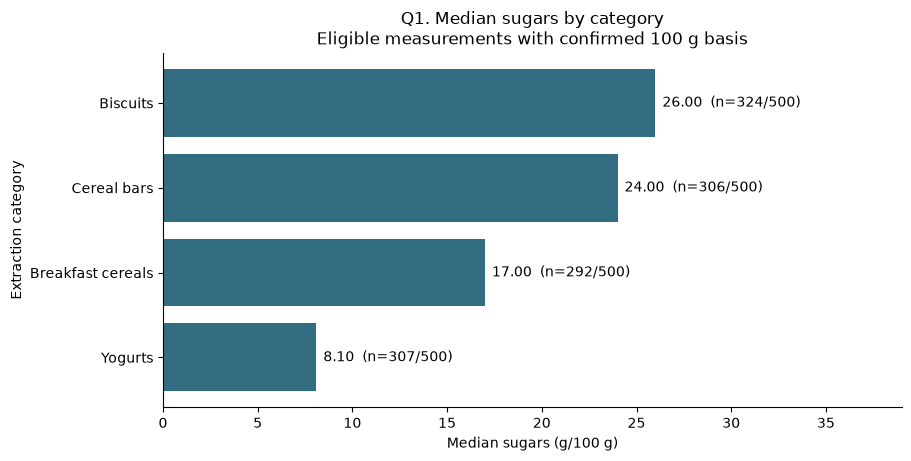

**Insight 1.** Biscuits have the highest sample median sugar content: 26.00 g/100 g among 324/500 memberships. Other medians are Breakfast cereals: 17.00 g/100 g (n=292); Yogurts: 8.10 g/100 g (n=307); Cereal bars: 24.00 g/100 g (n=306). The analysis covers 1,224 unique products across 1,229 eligible memberships. Missingness and basis filtering can affect this ordering; it is not a food-market estimate or a per-serving comparison.

In [4]:
sugar_summary, sugar_sample = mass_summary("sugars_g")
display(sugar_summary.rename(index=labels))
median_chart(sugar_summary, "Sugars", "phase4_01_median_sugar.png", "Q1")
winner = sugar_summary["median"].idxmax()
row = sugar_summary.loc[winner]
insights["Q1"] = (f"{labels[winner]} have the highest sample median sugar content: {row['median']:.2f} g/100 g "
                  f"among {int(row['n'])}/500 memberships. Other medians are "
                  + "; ".join(f"{labels[c]}: {sugar_summary.loc[c, 'median']:.2f} g/100 g (n={int(sugar_summary.loc[c, 'n'])})"
                              for c in order if c != winner)
                  + f". The analysis covers {sugar_sample.barcode.nunique():,} unique products across {len(sugar_sample):,} eligible memberships. "
                  "Missingness and basis filtering can affect this ordering; it is not a food-market estimate or a per-serving comparison.")
display(Markdown("**Insight 1.** " + insights["Q1"]))

## 4. Q2: Which category has the highest median protein content?

Use the protein-specific eligibility flag. A sugar or salt issue alone does not
remove an otherwise eligible protein observation. Medians limit the influence
of extremes without deleting statistical outliers.

,n,median,all_memberships,nonmass_or_unknown,mass_missing_or_flagged
category_id,,,,,
Breakfast cereals,292,9.4,500,206,2
Yogurts,313,3.5,500,176,11
Biscuits,325,6.8,500,168,7
Cereal bars,306,7.1,500,191,3


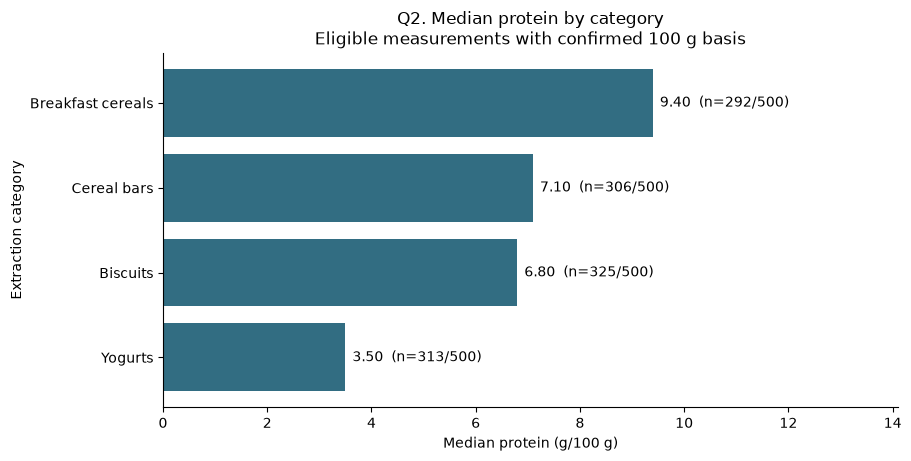

**Insight 2.** Breakfast cereals have the highest sample median protein: 9.40 g/100 g among 292/500 memberships. Other medians are Yogurts: 3.50 g/100 g (n=313); Biscuits: 6.80 g/100 g (n=325); Cereal bars: 7.10 g/100 g (n=306). There are 1,231 unique eligible products and 1,236 memberships. The selected mass-basis subset may differ from excluded products, and protein concentration alone is not an overall health measure.

In [5]:
protein_summary, protein_sample = mass_summary("protein_g")
display(protein_summary.rename(index=labels))
median_chart(protein_summary, "Protein", "phase4_02_median_protein.png", "Q2")
winner = protein_summary["median"].idxmax()
row = protein_summary.loc[winner]
insights["Q2"] = (f"{labels[winner]} have the highest sample median protein: {row['median']:.2f} g/100 g "
                  f"among {int(row['n'])}/500 memberships. Other medians are "
                  + "; ".join(f"{labels[c]}: {protein_summary.loc[c, 'median']:.2f} g/100 g (n={int(protein_summary.loc[c, 'n'])})"
                              for c in order if c != winner)
                  + f". There are {protein_sample.barcode.nunique():,} unique eligible products and {len(protein_sample):,} memberships. "
                  "The selected mass-basis subset may differ from excluded products, and protein concentration alone is not an overall health measure.")
display(Markdown("**Insight 2.** " + insights["Q2"]))

## 5. Q3: Which products have the highest valid protein per 100 kcal?

We independently recalculate `100 * protein / kcal`, check it against the saved
Phase 3 field, and then reuse that field. Valid means eligible under the implemented
rules, not independently verified nutrition. Known 100 ml products are allowed
because numerator and denominator have the same basis; no density conversion is
needed. Overall ranking uses unique barcodes before any category expansion.

Show the top ten, sorted by unrounded ratio descending, then exact barcode
ascending to break exact ties. Full names, brands, barcodes, bases and all category
memberships appear in the table. The chart abbreviates long names only for display.

,barcode,product_name,brand_name,all_categories,measurement_basis,protein_g_per_100,energy_kcal_per_100,protein_g_per_100kcal
0,5400101078673,Carrefour Sensation Skyr Nature 0% M.G.,Carrefour,Yogurts,100g,10.0,51.625239,19.37037
1,0034361482953,HiPro,Danone,Yogurts,100g,9.5,53.0,17.924528
2,4056489491217,Skyr,Milbona,Yogurts,100g,11.0,62.0,17.741935
3,3033491588136,Yaourt protéiné Hipro Vanille 0%mg - 2x160g,Danone,Yogurts,100g,9.4,53.125,17.694118
4,3033491482892,Hipro fruit citron,Danone,Yogurts,100g,9.3,53.125,17.505882
5,3273221114864,Skyr bio,Vrai,Yogurts,100g,9.3,54.0,17.222222
6,3560071495619,High protein vanille,Carrefour,Yogurts,100g,9.2,54.0,17.037037
7,3033491690334,HiPRO Saveur Coco,Danone,Yogurts,100g,9.4,56.0,16.785714
8,3560071495640,High protein Myrtille,Carrefour,Yogurts,100g,9.2,55.0,16.727273
9,3523230063715,Skyr au lait de chèvre,Soignon,Yogurts,100g,9.1,55.0,16.545455


,eligible_unique_products
measurement_basis,
100g,1199
100ml,5


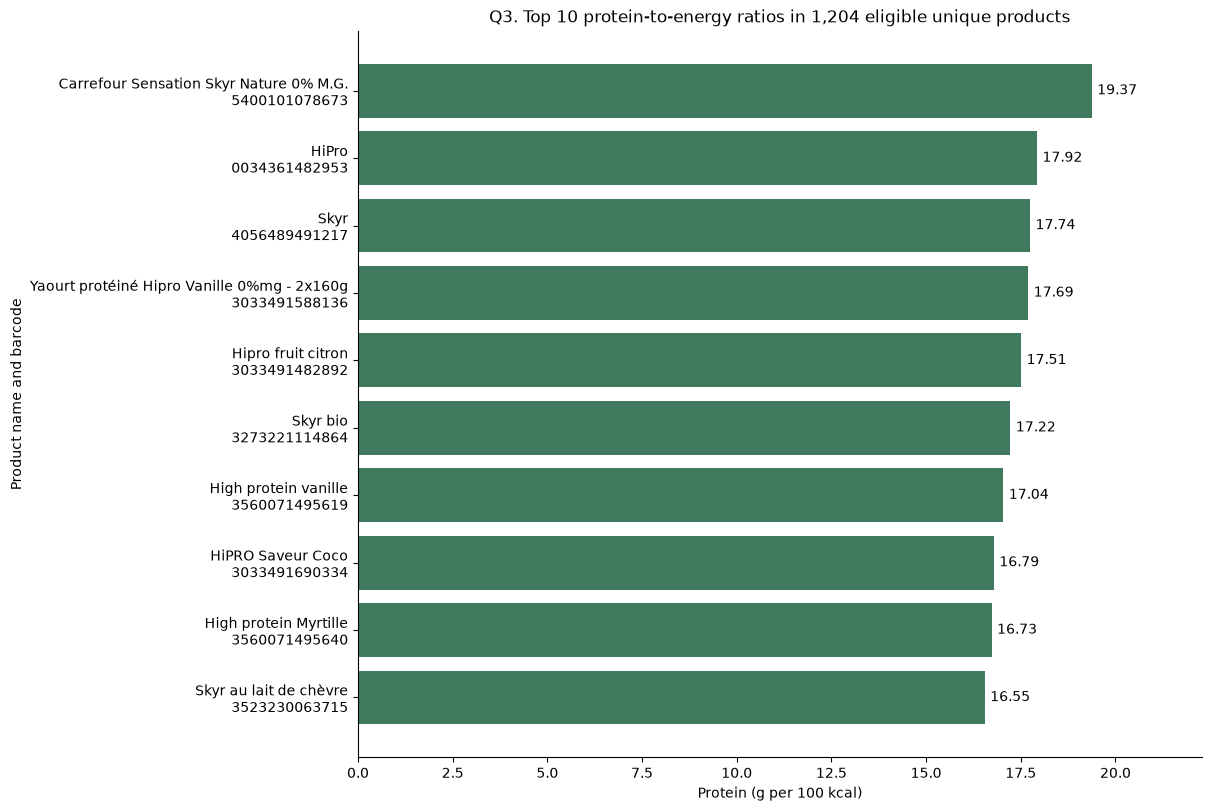

**Insight 3.** Carrefour Sensation Skyr Nature 0% M.G. (5400101078673) ranks first at 19.37 g protein/100 kcal, using 10.00 g protein and 51.62524 kcal per reported 100 units (basis 100g). The next two are HiPro (0034361482953): 17.92; Skyr (4056489491217): 17.74 g/100 kcal. The ranking includes 1,204/1,987 products, including 5 with a volume basis. Ratios are sensitive to reported energy and do not establish overall product health or serving-level protein intake.

In [6]:
ratio_allowed = (unique_products.protein_g_eligible & unique_products.energy_kcal_eligible
                 & unique_products.measurement_basis.isin(["100g", "100ml"])
                 & unique_products.energy_kcal_per_100.gt(0))
recalculated = (100 * unique_products.protein_g_per_100
                / unique_products.energy_kcal_per_100.where(ratio_allowed)).where(ratio_allowed)
saved_ratio = unique_products.protein_g_per_100kcal
assert recalculated.notna().equals(saved_ratio.notna())
np.testing.assert_allclose(recalculated.dropna().astype(float), saved_ratio.dropna().astype(float), rtol=1e-12, atol=1e-12)
assert np.isfinite(saved_ratio.dropna()).all()
ranked = unique_products.loc[ratio_allowed & saved_ratio.notna()].copy()
category_text = members.groupby("barcode").category_name.agg(lambda names: "; ".join(sorted(names)))
ranked["all_categories"] = ranked.barcode.map(category_text)
ranked = ranked.sort_values(["protein_g_per_100kcal", "barcode"], ascending=[False, True], kind="stable")
top10 = ranked.head(10)
assert ranked.barcode.is_unique and len(top10) == 10
display(top10[["barcode", "product_name", "brand_name", "all_categories", "measurement_basis",
               "protein_g_per_100", "energy_kcal_per_100", "protein_g_per_100kcal"]].reset_index(drop=True))
display(ranked.measurement_basis.value_counts().rename("eligible_unique_products").to_frame())
plot_rows = top10.iloc[::-1]
tick_labels = [textwrap.shorten(str(row.product_name) if pd.notna(row.product_name) else "Name missing", width=43, placeholder="...")
               + "\n" + row.barcode for row in plot_rows.itertuples()]
fig, ax = plt.subplots(figsize=(12, 8), layout="constrained")
bars = ax.barh(tick_labels, plot_rows.protein_g_per_100kcal.astype(float), color="#407b60")
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set(xlabel="Protein (g per 100 kcal)", ylabel="Product name and barcode",
       title=f"Q3. Top 10 protein-to-energy ratios in {len(ranked):,} eligible unique products",
       xlim=(0, float(top10.protein_g_per_100kcal.max()) * 1.15))
save_chart(fig, "phase4_03_top_protein_per_100kcal.png")
leader = top10.iloc[0]
insights["Q3"] = (f"{leader.product_name} ({leader.barcode}) ranks first at {leader.protein_g_per_100kcal:.2f} g protein/100 kcal, "
                  f"using {leader.protein_g_per_100:.2f} g protein and {leader.energy_kcal_per_100:.5f} kcal per reported 100 units "
                  f"(basis {leader.measurement_basis}). The next two are "
                  + "; ".join(f"{r.product_name} ({r.barcode}): {r.protein_g_per_100kcal:.2f}" for r in top10.iloc[1:3].itertuples())
                  + f" g/100 kcal. The ranking includes {len(ranked):,}/{len(unique_products):,} products, "
                  f"including {int(ranked.measurement_basis.eq('100ml').sum())} with a volume basis. "
                  "Ratios are sensitive to reported energy and do not establish overall product health or serving-level protein intake.")
display(Markdown("**Insight 3.** " + insights["Q3"]))

## 6. Q4: Which categories have the highest nutritional data completeness?

Use Phase 3's reported completeness: 100 times the number of reported values in
eight fields divided by eight. The fields are kcal, protein, carbohydrates, sugars,
fat, saturated fat, fiber and salt. kJ is excluded to avoid counting energy twice.

All 500 memberships per category are included, even products with no nutrients.
The **mean** completeness distinguishes coverage when medians tie at 100%.
The table also shows medians, complete-case counts and mean numeric eligibility
coverage. Eligibility coverage is a separate diagnostic; neither is a health score
or confirmation of mass basis. No measurement values are averaged for this question.

,n,mean_reported_pct,median_reported_pct,complete_products,mean_eligible_pct
category_id,,,,,
Breakfast cereals,500,98.675,100.0,489,98.35
Yogurts,500,88.95,87.5,225,88.125
Biscuits,500,96.625,100.0,442,96.075
Cereal bars,500,98.525,100.0,478,97.475


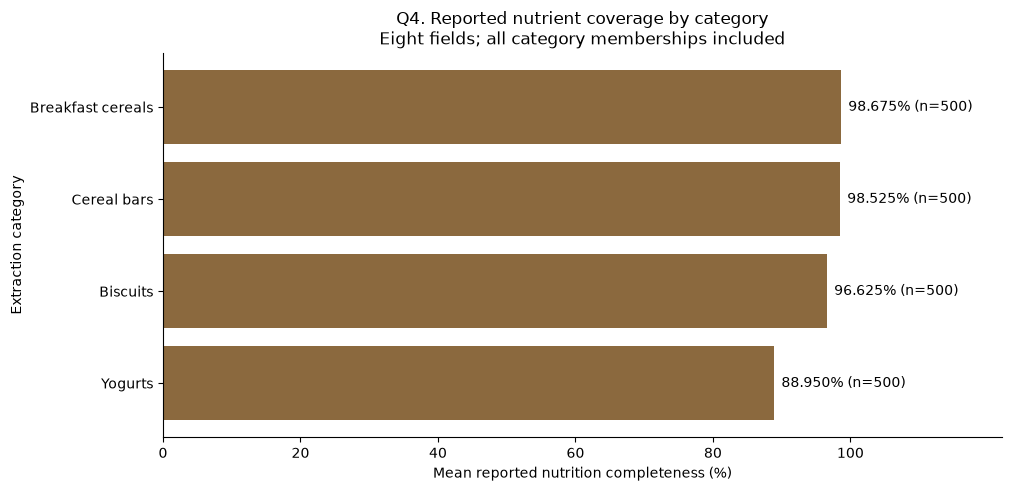

**Insight 4.** Mean reported completeness ranks Breakfast cereals 98.675%; Cereal bars 98.525%; Biscuits 96.625%; Yogurts 88.950%, with 500 memberships in each group. The highest-to-lowest gap is 9.725 percentage points. Reported coverage includes flagged observations; it measures documentation, not nutritional quality or analysis eligibility. Overall coverage is 95.6719% across 1,987 unique products, without overlap duplication.

In [7]:
coverage_check = unique_products[[f"reported_{n}_per_100" for n in core]].notna().mean(axis=1).mul(100)
np.testing.assert_allclose(coverage_check.astype(float), unique_products.nutrition_completeness_pct.astype(float), rtol=1e-12)
members = members.assign(eligible_coverage_pct=members[[f"{n}_eligible" for n in core]].mean(axis=1).mul(100))
completeness = members.groupby("category_id").agg(
    n=("barcode", "size"), mean_reported_pct=("nutrition_completeness_pct", "mean"),
    median_reported_pct=("nutrition_completeness_pct", "median"),
    complete_products=("nutrition_completeness_pct", lambda x: int(x.eq(100).sum())),
    mean_eligible_pct=("eligible_coverage_pct", "mean"),
).reindex(order)
assert completeness.n.eq(member_counts).all()
display(completeness.rename(index=labels))
plot_rows = completeness.sort_values("mean_reported_pct")
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
bars = ax.barh([labels[c] for c in plot_rows.index], plot_rows.mean_reported_pct.astype(float), color="#8b693e")
ax.bar_label(bars, labels=[f"{r.mean_reported_pct:.3f}% (n={int(r.n)})" for r in plot_rows.itertuples()], padding=5)
ax.set(xlabel="Mean reported nutrition completeness (%)", ylabel="Extraction category", xlim=(0, 122),
       title="Q4. Reported nutrient coverage by category\nEight fields; all category memberships included")
ax.set_xticks([0, 20, 40, 60, 80, 100])
save_chart(fig, "phase4_04_nutrition_completeness.png")
ordered = completeness.sort_values("mean_reported_pct", ascending=False)
insights["Q4"] = ("Mean reported completeness ranks "
                  + "; ".join(f"{labels[c]} {r.mean_reported_pct:.3f}%" for c, r in ordered.iterrows())
                  + f", with 500 memberships in each group. The highest-to-lowest gap is "
                  f"{ordered.mean_reported_pct.iloc[0] - ordered.mean_reported_pct.iloc[-1]:.3f} percentage points. "
                  "Reported coverage includes flagged observations; it measures documentation, not nutritional quality or analysis eligibility. "
                  f"Overall coverage is {unique_products.nutrition_completeness_pct.mean():.4f}% across {len(unique_products):,} unique products, without overlap duplication.")
display(Markdown("**Insight 4.** " + insights["Q4"]))

## 7. Q5: How are Nutri-Score grades distributed across categories?

Use the source-provided grades without recalculating them from nutrients. The
denominator is **all 500 memberships per category**, including unknown and not
applicable grades. A not-applicable value is not a poor grade. Numeric/basis
filters are not applied to this separate classification question. Percentages
are sample descriptions, not market prevalence or causal comparisons.

Nutri-Score state (counts),A,B,C,D,E,Unknown,Not applicable
category_id,,,,,,,
Breakfast cereals,155,55,188,77,19,6,0
Yogurts,107,91,206,24,31,33,8
Biscuits,6,26,79,107,268,12,2
Cereal bars,20,11,130,211,73,6,49


Nutri-Score state (% of all memberships),A,B,C,D,E,Unknown,Not applicable
category_id,,,,,,,
Breakfast cereals,31.0,11.0,37.6,15.4,3.8,1.2,0.0
Yogurts,21.4,18.2,41.2,4.8,6.2,6.6,1.6
Biscuits,1.2,5.2,15.8,21.4,53.6,2.4,0.4
Cereal bars,4.0,2.2,26.0,42.2,14.6,1.2,9.8


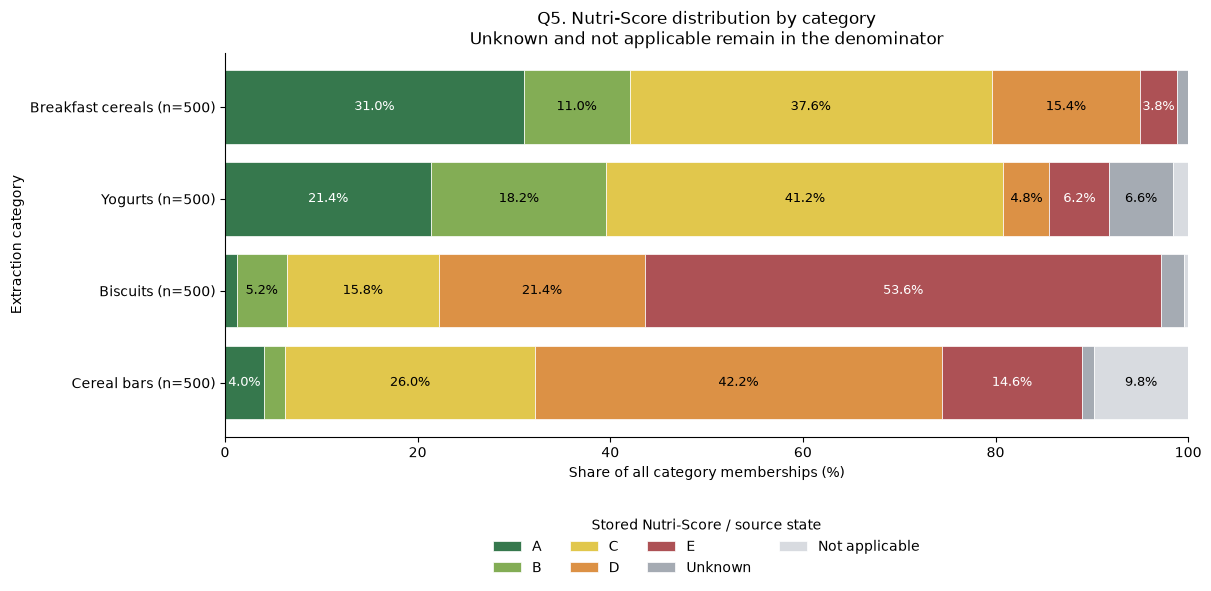

**Insight 5.** The most frequent states are Breakfast cereals: C (188/500, 37.6%); Yogurts: C (206/500, 41.2%); Biscuits: E (268/500, 53.6%); Cereal bars: D (211/500, 42.2%). D/E shares are Breakfast cereals 19.2%; Yogurts 11.0%; Biscuits 75.0%; Cereal bars 56.8%. Across unique products, 116 lack a grade: 57 unknown and 59 not applicable. These stored classifications have incomplete coverage and were not independently recalculated; they do not establish a causal category effect.

In [8]:
levels = ["A", "B", "C", "D", "E", "Unknown", "Not applicable"]
assert products.nutriscore_status.isin(["reported", "unknown", "not_applicable"]).all()
assert products.nutriscore_grade.notna().eq(products.nutriscore_status.eq("reported")).all()
grade = members.nutriscore_grade.str.upper().fillna(
    members.nutriscore_status.map({"unknown": "Unknown", "not_applicable": "Not applicable"}))
assert grade.isin(levels).all()
grade_counts = pd.crosstab(members.category_id, grade).reindex(index=order, columns=levels, fill_value=0)
grade_pct = grade_counts.div(member_counts, axis=0).mul(100)
assert grade_counts.sum(axis=1).eq(member_counts).all()
np.testing.assert_allclose(grade_pct.sum(axis=1), 100)
display(grade_counts.rename(index=labels).rename_axis(columns="Nutri-Score state (counts)"))
display(grade_pct.rename(index=labels).round(1).rename_axis(columns="Nutri-Score state (% of all memberships)"))
fig, ax = plt.subplots(figsize=(12, 5.8), layout="constrained")
colors = ["#36784d", "#83ad55", "#e1c74c", "#dc9145", "#ad5155", "#a5abb3", "#d8dbe0"]
left = np.zeros(len(order))
for level, color in zip(levels, colors):
    width = grade_pct[level].to_numpy(dtype=float)
    ax.barh([labels[c] + " (n=500)" for c in order], width, left=left, color=color, label=level, edgecolor="white", linewidth=.5)
    for y, (start, value) in enumerate(zip(left, width)):
        if value >= 3:
            ax.text(start + value/2, y, f"{value:.1f}%", ha="center", va="center", fontsize=9,
                    color="white" if level in ["A", "E"] else "black")
    left += width
ax.invert_yaxis()
ax.set(xlabel="Share of all category memberships (%)", ylabel="Extraction category", xlim=(0, 100),
       title="Q5. Nutri-Score distribution by category\nUnknown and not applicable remain in the denominator")
ax.legend(title="Stored Nutri-Score / source state", ncols=4, loc="upper center", bbox_to_anchor=(.5, -.18), frameon=False)
save_chart(fig, "phase4_05_nutriscore_distribution.png")
de = grade_counts[["D", "E"]].sum(axis=1)
insights["Q5"] = ("The most frequent states are "
                  + "; ".join(f"{labels[c]}: {grade_counts.loc[c].idxmax()} ({grade_counts.loc[c].max()}/500, {grade_pct.loc[c].max():.1f}%)" for c in order)
                  + ". D/E shares are " + "; ".join(f"{labels[c]} {de[c]/500*100:.1f}%" for c in order)
                  + f". Across unique products, {int(products.nutriscore_grade.isna().sum())} lack a grade: "
                  f"{int(products.nutriscore_status.eq('unknown').sum())} unknown and {int(products.nutriscore_status.eq('not_applicable').sum())} not applicable. "
                  "These stored classifications have incomplete coverage and were not independently recalculated; they do not establish a causal category effect.")
display(Markdown("**Insight 5.** " + insights["Q5"]))

## 8. Consolidated findings, limitations and validation

Each answer below comes from the calculated tables above. The charts and prose
use the same variables, so rerunning the notebook recalculates the findings.

- The four API categories were sampled nonrandomly, with fixed extraction targets.
  Neither category sizes nor product rankings represent the whole food market.
- Missingness and strict basis/eligibility exclusions can select better documented
  products; different nutrients use different available-case samples.
- Shared category memberships are retained. Comparisons are descriptive and do
  not assume independent random groups. No significance or causal claim is made.
- Source measurement and classification errors can remain after screening.
  Ranking protein-to-energy ratios does not measure overall health, protein per
  serving or value for money. Small denominators can affect ratios.
- Completeness measures reported fields, not correctness. Primary brands are
  first-listed source labels, not independently verified corporate identities.
- No imputation, new cleaning, outlier deletion, API calls, database loading,
  SQL, machine learning or dashboard work is performed here.

In [9]:
assert set(insights) == {"Q1", "Q2", "Q3", "Q4", "Q5"}
for question, text in insights.items():
    display(Markdown(f"**{question}.** {text}"))

# Independent per-category selections verify the expanded-join calculations.
for category in order:
    barcodes = set(links.loc[links.category_id.eq(category), "barcode"])
    independent = nutrition.loc[nutrition.barcode.isin(barcodes)]
    assert len(independent) == 500
    for nutrient, summary in [("sugars_g", sugar_summary), ("protein_g", protein_summary)]:
        chosen = independent.loc[independent.measurement_basis.eq("100g") & independent[f"{nutrient}_eligible"], f"{nutrient}_per_100"]
        assert len(chosen) == summary.loc[category, "n"]
        assert np.isclose(chosen.median(), summary.loc[category, "median"])
    assert np.isclose(independent.nutrition_completeness_pct.mean(), completeness.loc[category, "mean_reported_pct"])
    selected_products = products.loc[products.barcode.isin(barcodes)]
    for grade in list("ABCDE"):
        assert int(selected_products.nutriscore_grade.eq(grade.lower()).sum()) == grade_counts.loc[category, grade]

assert ranked.protein_g_per_100kcal.is_monotonic_decreasing
assert ranked.barcode.nunique() == len(ranked)
assert len(chart_files) == len(set(chart_files)) == 5
for filename in chart_files:
    pixels = plt.imread(FIGURES / filename)
    assert pixels.shape[0] >= 400 and pixels.shape[1] >= 800 and pixels.std() > 0
for name, original in input_copies.items():
    pd.testing.assert_frame_equal(tables[name], original)
assert protected_snapshot() == before, "A protected input changed"
print(f"PASS: five answers and five exported charts; all {len(before)} protected files and input DataFrames unchanged.")
print("PASS: joins, field eligibility, mass basis, ratios, denominators and independent category calculations reconcile.")

**Q1.** Biscuits have the highest sample median sugar content: 26.00 g/100 g among 324/500 memberships. Other medians are Breakfast cereals: 17.00 g/100 g (n=292); Yogurts: 8.10 g/100 g (n=307); Cereal bars: 24.00 g/100 g (n=306). The analysis covers 1,224 unique products across 1,229 eligible memberships. Missingness and basis filtering can affect this ordering; it is not a food-market estimate or a per-serving comparison.

**Q2.** Breakfast cereals have the highest sample median protein: 9.40 g/100 g among 292/500 memberships. Other medians are Yogurts: 3.50 g/100 g (n=313); Biscuits: 6.80 g/100 g (n=325); Cereal bars: 7.10 g/100 g (n=306). There are 1,231 unique eligible products and 1,236 memberships. The selected mass-basis subset may differ from excluded products, and protein concentration alone is not an overall health measure.

**Q3.** Carrefour Sensation Skyr Nature 0% M.G. (5400101078673) ranks first at 19.37 g protein/100 kcal, using 10.00 g protein and 51.62524 kcal per reported 100 units (basis 100g). The next two are HiPro (0034361482953): 17.92; Skyr (4056489491217): 17.74 g/100 kcal. The ranking includes 1,204/1,987 products, including 5 with a volume basis. Ratios are sensitive to reported energy and do not establish overall product health or serving-level protein intake.

**Q4.** Mean reported completeness ranks Breakfast cereals 98.675%; Cereal bars 98.525%; Biscuits 96.625%; Yogurts 88.950%, with 500 memberships in each group. The highest-to-lowest gap is 9.725 percentage points. Reported coverage includes flagged observations; it measures documentation, not nutritional quality or analysis eligibility. Overall coverage is 95.6719% across 1,987 unique products, without overlap duplication.

**Q5.** The most frequent states are Breakfast cereals: C (188/500, 37.6%); Yogurts: C (206/500, 41.2%); Biscuits: E (268/500, 53.6%); Cereal bars: D (211/500, 42.2%). D/E shares are Breakfast cereals 19.2%; Yogurts 11.0%; Biscuits 75.0%; Cereal bars 56.8%. Across unique products, 116 lack a grade: 57 unknown and 59 not applicable. These stored classifications have incomplete coverage and were not independently recalculated; they do not establish a causal category effect.

PASS: five answers and five exported charts; all 55 protected files and input DataFrames unchanged.
PASS: joins, field eligibility, mass basis, ratios, denominators and independent category calculations reconcile.
